# Concert Tours Data Cleaning

**Goal:** clean a small table of the 20 highest-grossing concert tours by women so that it can be used for analysis.

The raw data was copied from a Wikipedia table. It contains typical web-scraping problems:

- money values stored as text (`$780,000,000`)
- footnote markers inside values (`7[2]`, `$229,100,000[b]`, `Sticky & Sweet Tour ‡[4][a]`)
- hidden non-breaking spaces in column names
- a year range stored as text (`2008–2009`)
- many missing values in the ranking columns

**Data source:** [List of highest-grossing concert tours by women](https://en.wikipedia.org/wiki/List_of_highest-grossing_concert_tours_by_women), Wikipedia, licensed under CC BY-SA 4.0.

## 1. Load and inspect the data

In [1]:
import pandas as pd

df = pd.read_csv("data/concert_tours_raw.csv")
df.head()

,Rank,Peak,All Time Peak,Actual gross,Adjusted gross (in 2022 dollars),Artist,Tour title,Year(s),Shows,Average gross,Ref.
0,1,1,2,"$780,000,000","$780,000,000",Taylor Swift,The Eras Tour †,2023–2024,56,"$13,928,571",[1]
1,2,1,7[2],"$579,800,000","$579,800,000",Beyoncé,Renaissance World Tour,2023,56,"$10,353,571",[3]
2,3,1[4],2[5],"$411,000,000","$560,622,615",Madonna,Sticky & Sweet Tour ‡[4][a],2008–2009,85,"$4,835,294",[6]
3,4,2[7],10[7],"$397,300,000","$454,751,555",Pink,Beautiful Trauma World Tour,2018–2019,156,"$2,546,795",[7]
4,5,2[4],NaN,"$345,675,146","$402,844,849",Taylor Swift,Reputation Stadium Tour,2018,53,"$6,522,173",[8]


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype
---  ------                            --------------  -----
 0   Rank                              20 non-null     int64
 1   Peak                              9 non-null      str  
 2   All Time Peak                     6 non-null      str  
 3   Actual gross                      20 non-null     str  
 4   Adjusted gross (in 2022 dollars)  20 non-null     str  
 5   Artist                            20 non-null     str  
 6   Tour title                        20 non-null     str  
 7   Year(s)                           20 non-null     str  
 8   Shows                             20 non-null     int64
 9   Average gross                     20 non-null     str  
 10  Ref.                              20 non-null     str  
dtypes: int64(2), str(9)
memory usage: 1.8 KB


Only `Rank` and `Shows` are numeric. All money columns are text, and `Peak` / `All Time Peak` have many missing values.

## 2. Clean the column names

Make column names lowercase and remove extra spaces.

When I first tried to select `actual gross`, pandas raised a `KeyError`. Printing the names with `repr()` showed the reason: some names contain a non-breaking space (`\xa0`) instead of a normal space.

In [3]:
df.columns = df.columns.str.strip().str.lower()

In [4]:
for col in df.columns:
    print(repr(col))

'rank'
'peak'
'all time peak'
'actual\xa0gross'
'adjusted\xa0gross (in 2022 dollars)'
'artist'
'tour title'
'year(s)'
'shows'
'average gross'
'ref.'


In [5]:
df.columns = df.columns.str.replace('\xa0', ' ', regex=False)

for col in df.columns:
    print(repr(col))

'rank'
'peak'
'all time peak'
'actual gross'
'adjusted gross (in 2022 dollars)'
'artist'
'tour title'
'year(s)'
'shows'
'average gross'
'ref.'


## 3. Convert money columns to numbers

Columns: `actual gross`, `adjusted gross (in 2022 dollars)`, `average gross`.

A simple `replace('$', '')` was not enough, because some values contain footnotes such as `$229,100,000[b]`. So I first remove footnotes in square brackets, then keep only digits and dots, and convert to numbers.

In [6]:
money_cols = ['actual gross', 'adjusted gross (in 2022 dollars)', 'average gross']

for col in money_cols:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(r'\[.*?\]', '', regex=True)   # remove footnotes like [b]
        .str.replace(r'[^\d.]', '', regex=True)     # keep only digits and dots
    )
    df[col] = pd.to_numeric(df[col], errors='coerce')

df[money_cols].head()

,actual gross,adjusted gross (in 2022 dollars),average gross
0,780000000,780000000,13928571
1,579800000,579800000,10353571
2,411000000,560622615,4835294
3,397300000,454751555,2546795
4,345675146,402844849,6522173


## 4. Clean `peak` and `all time peak`

Remove footnotes such as `1[4]` and convert to numbers. Missing values stay as `NaN`: a missing peak means the tour was not listed in that ranking, so filling it with a guess would be wrong.

In [7]:
for col in ['peak', 'all time peak']:
    df[col] = df[col].astype(str).str.replace(r'\[.*?\]', '', regex=True)
    df[col] = pd.to_numeric(df[col], errors='coerce')

df[['peak', 'all time peak']].isna().sum()

peak             11
all time peak    14
dtype: int64

## 5. Clean `tour title`

Some tour titles contain table symbols (`†`, `‡`, `*`) and footnotes (`[4][a]`). These belong to the Wikipedia layout, not to the tour name.

In [8]:
df['tour title'] = (
    df['tour title']
    .str.replace(r'\[.*?\]', '', regex=True)
    .str.replace(r'[†‡*]', '', regex=True)
    .str.strip()
)

df['tour title'].tolist()

['The Eras Tour',
 'Renaissance World Tour',
 'Sticky & Sweet Tour',
 'Beautiful Trauma World Tour',
 'Reputation Stadium Tour',
 'The MDNA Tour',
 'Taking Chances World Tour',
 'Summer Carnival',
 'The Formation World Tour',
 'The 1989 World Tour',
 'The Mrs. Carter Show World Tour',
 'The Monster Ball Tour',
 'Prismatic World Tour',
 'Living Proof: The Farewell Tour',
 'Confessions Tour',
 'The Truth About Love Tour',
 'Born This Way Ball',
 'Rebel Heart Tour',
 'Adele Live 2016',
 'The Red Tour']

## 6. Extract the start year from `year(s)`

In [9]:
df['start_year'] = (
    df['year(s)']
    .str.extract(r'(\d{4})')[0]
    .astype('Int64')
)

df[['year(s)', 'start_year']].head()

,year(s),start_year
0,2023–2024,2023
1,2023,2023
2,2008–2009,2008
3,2018–2019,2018
4,2018,2018


## 7. Descriptive statistics and outliers

In [10]:
# show numbers without scientific notation, with 2 decimals
pd.options.display.float_format = '{:,.2f}'.format

df.describe()

,rank,peak,all time peak,actual gross,adjusted gross (in 2022 dollars),shows,average gross,start_year
count,20.00,9.00,6.00,20.00,20.00,20.00,20.00,20.00
mean,10.45,1.56,7.50,"287,950,903.25","343,878,092.05",110.00,"3,726,571.15","2,013.85"
std,5.94,0.53,4.81,"156,328,421.04","151,462,683.69",66.51,"3,393,339.60",5.62
min,1.00,1.00,2.00,"150,000,000.00","185,423,109.00",41.00,"615,385.00","2,002.00"
25%,5.75,1.00,3.25,"191,500,000.00","245,755,688.25",59.00,"1,647,508.00","2,011.25"
50%,10.50,2.00,8.50,"239,750,000.00","297,488,872.00",87.00,"2,342,100.00","2,013.50"
75%,15.25,2.00,10.00,"315,287,558.75","392,445,084.25",134.50,"4,933,024.25","2,016.50"
max,20.00,2.00,14.00,"780,000,000.00","780,000,000.00",325.00,"13,928,571.00","2,023.00"


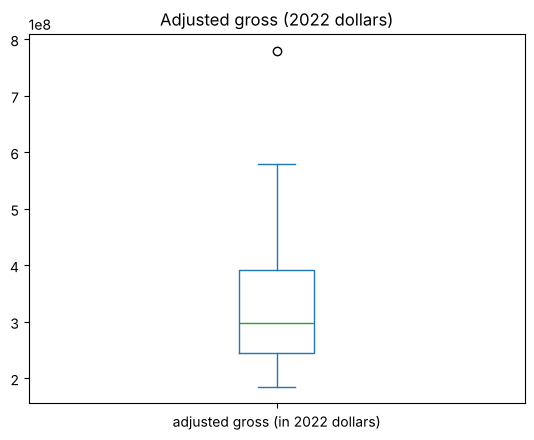

In [11]:
df['adjusted gross (in 2022 dollars)'].plot(kind='box', title='Adjusted gross (2022 dollars)');

### Check: is `average gross` consistent with `actual gross / shows`?

In [12]:
df['calc_avg'] = df['actual gross'] / df['shows']
df['diff'] = (df['average gross'] - df['calc_avg']).abs()

df[['artist', 'tour title', 'average gross', 'calc_avg', 'diff']].sort_values('diff', ascending=False).head()

,artist,tour title,average gross,calc_avg,diff
11,Lady Gaga,The Monster Ball Tour,1118227,"1,120,197.04","1,970.04"
4,Taylor Swift,Reputation Stadium Tour,6522173,"6,522,172.57",0.43
0,Taylor Swift,The Eras Tour,13928571,"13,928,571.43",0.43
1,Beyoncé,Renaissance World Tour,10353571,"10,353,571.43",0.43
8,Beyoncé,The Formation World Tour,5226215,"5,226,215.43",0.43


For almost all tours the difference is below 1 dollar (rounding). Only Lady Gaga's *The Monster Ball Tour* differs by about 1,970 dollars per show. This is small, but worth noting: the source value may be rounded or calculated differently.

### Outliers in average gross per show (IQR method)

In [13]:
Q1 = df['calc_avg'].quantile(0.25)
Q3 = df['calc_avg'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_outliers = df[(df['calc_avg'] < lower) | (df['calc_avg'] > upper)]
df_outliers[['artist', 'tour title', 'shows', 'calc_avg']]

,artist,tour title,shows,calc_avg
0,Taylor Swift,The Eras Tour,56,"13,928,571.43"
1,Beyoncé,Renaissance World Tour,56,"10,353,571.43"


These outliers are real values, not data errors: recent stadium tours earn much more per show. I keep them in the data.

## 8. Duplicates and artist names

In [14]:
print('Fully duplicated rows:', df.duplicated().sum())
df[df.duplicated(subset=['artist', 'start_year'], keep=False)]

Fully duplicated rows: 0


,rank,peak,all time peak,actual gross,adjusted gross (in 2022 dollars),artist,tour title,year(s),shows,average gross,ref.,start_year,calc_avg,diff


In [15]:
df['artist_clean'] = (
    df['artist']
    .str.strip()
    .str.lower()
    .str.replace(r'\s+', ' ', regex=True)
)

df['artist_clean'].value_counts()

artist_clean
taylor swift    4
madonna         4
beyoncé         3
pink            3
lady gaga       2
celine dion     1
katy perry      1
cher            1
adele           1
Name: count, dtype: int64

No duplicate rows and no spelling variants of artist names were found.

## 9. Final dataset

In [16]:
df_clean = df.drop(columns=['ref.', 'calc_avg', 'diff', 'artist_clean'])
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   rank                              20 non-null     int64  
 1   peak                              9 non-null      float64
 2   all time peak                     6 non-null      float64
 3   actual gross                      20 non-null     int64  
 4   adjusted gross (in 2022 dollars)  20 non-null     int64  
 5   artist                            20 non-null     str    
 6   tour title                        20 non-null     str    
 7   year(s)                           20 non-null     str    
 8   shows                             20 non-null     int64  
 9   average gross                     20 non-null     int64  
 10  start_year                        20 non-null     Int64  
dtypes: Int64(1), float64(2), int64(5), str(3)
memory usage: 1.9 KB


In [17]:
df_clean.to_csv('data/concert_tours_clean.csv', index=False)
df_clean.head()

,rank,peak,all time peak,actual gross,adjusted gross (in 2022 dollars),artist,tour title,year(s),shows,average gross,start_year
0,1,1.00,2.00,780000000,780000000,Taylor Swift,The Eras Tour,2023–2024,56,13928571,2023
1,2,1.00,7.00,579800000,579800000,Beyoncé,Renaissance World Tour,2023,56,10353571,2023
2,3,1.00,2.00,411000000,560622615,Madonna,Sticky & Sweet Tour,2008–2009,85,4835294,2008
3,4,2.00,10.00,397300000,454751555,Pink,Beautiful Trauma World Tour,2018–2019,156,2546795,2018
4,5,2.00,NaN,345675146,402844849,Taylor Swift,Reputation Stadium Tour,2018,53,6522173,2018


## Summary

- Fixed hidden non-breaking spaces in column names.
- Converted three money columns from text to numbers, including values with footnotes.
- Removed footnotes and table symbols from `peak`, `all time peak` and `tour title`.
- Added `start_year` from the year range.
- Checked consistency of `average gross`, outliers and duplicates.
- Saved the result to `data/concert_tours_clean.csv`.